# Decision Tree

A tree asks yes/no questions (*"is feature f ≤ t?"*) until it reaches a leaf, which predicts a class.
Every question is chosen greedily to make the two groups as pure as possible (Gini or entropy).
The implementation is in `trees.py` (NumPy only); this notebook runs the experiments.

| Hyper-parameter | Values tested |
|---|---|
| `max_depth` | 2 – 30, None |
| `min_samples_split` | 2 – 400 |
| `min_samples_leaf` | 1 – 100 |
| `criterion` | Gini, entropy |
| `n_bins` (candidate thresholds) | 8 – 256 |
| features | raw vs LDA projection |

## 1. Setup

In [1]:
import os
import sys

if not os.path.exists("common.py"):      # run from the project folder
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import common
import trees

common.set_seed(42)
os.makedirs("decision_tree/outputs", exist_ok=True)
os.makedirs("report/figures", exist_ok=True)
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

python 3.9.6 | numpy 2.0.2 | pandas 2.3.3


## 2. How the tree is built

* **Impurity** of a group: Gini `1 - Σ p_c²` or entropy `-Σ p_c log2 p_c`.
* **Gain** of a question: `impurity(parent) - (n_L/n)·impurity(left) - (n_R/n)·impurity(right)`.
* At each node the question with the largest gain is kept; a node becomes a leaf when it is pure, `max_depth` is reached,
  it has fewer than `min_samples_split` rows, or no allowed split improves it.
* **Candidate thresholds:** like Lab 5 we test every feature, but with up to 63 quantile thresholds per feature instead of
  every midpoint (20,000 rows). One `np.bincount` gives the class counts of every (feature, threshold) at once.
* 85% of the image values are 0, so we also take quantiles of the non-zero values; otherwise most thresholds would be 0 (section 5.5).

## 3. Toy example

Class 1 if `x0 + x1 > 1`. A tree cuts one feature at a time, so it builds a staircase around the diagonal.

x0 <= 0.39 ?
    -> class 0   (63 rows)
else:
    -> class 1   (137 rows)


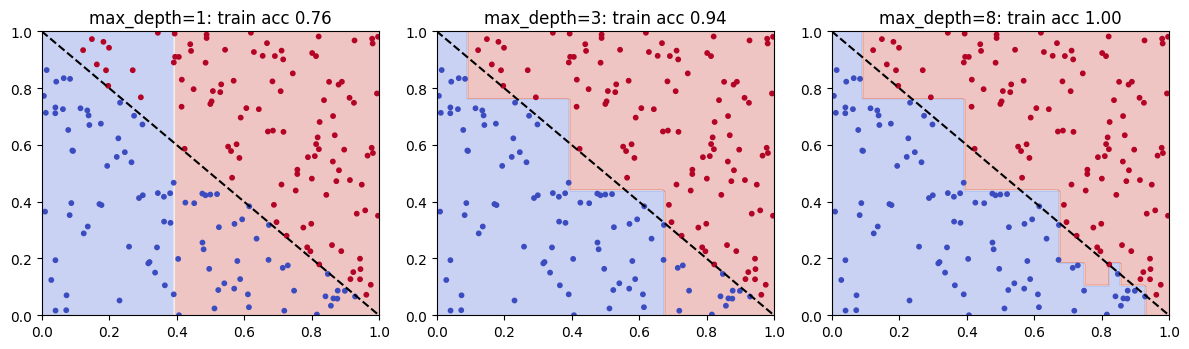

In [2]:
rng = np.random.default_rng(0)
X_toy = rng.random((200, 2))
y_toy = (X_toy[:, 0] + X_toy[:, 1] > 1).astype(int)


def print_tree(tree, node=0, depth=0, names=None):
    pad = "    " * depth
    if tree.feature[node] < 0:                                  # leaf
        print(f"{pad}-> class {tree.value[node].argmax()}   ({tree.n_rows[node]} rows)")
        return
    f = tree.feature[node]
    print(f"{pad}{names[f] if names else f'feature {f}'} <= {tree.threshold[node]:.2f} ?")
    print_tree(tree, tree.left[node], depth + 1, names)
    print(f"{pad}else:")
    print_tree(tree, tree.right[node], depth + 1, names)


xx, yy = np.meshgrid(np.linspace(0, 1, 150), np.linspace(0, 1, 150))
grid = np.c_[xx.ravel(), yy.ravel()]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, depth in zip(axes, [1, 3, 8]):
    toy = trees.DecisionTree(max_depth=depth).fit(X_toy, y_toy, n_classes=2)
    if depth == 1:
        print_tree(toy, names=["x0", "x1"])
    ax.contourf(xx, yy, toy.predict(grid).reshape(xx.shape), alpha=0.3, cmap="coolwarm")
    ax.scatter(X_toy[:, 0], X_toy[:, 1], c=y_toy, cmap="coolwarm", s=10)
    ax.plot([0, 1], [1, 0], "k--")
    ax.set_title(f"max_depth={depth}: train acc {common.accuracy(y_toy, toy.predict(X_toy)):.2f}")
plt.tight_layout()
plt.show()

## 4. Data and validation split

Same stratified 80/20 split as every model (`common.stratified_split`, seed 42). Trees need no scaling:
scaling a feature only moves its threshold.

In [3]:
X_image, y_image, X_image_test, image_test_ids = common.load_task("image")
X_sent, y_sent, X_sent_test, sent_test_ids = common.load_task("sentiment")

DATA = {"image": (X_image, y_image), "sentiment": (X_sent, y_sent)}
TEST = {"image": (X_image_test, image_test_ids), "sentiment": (X_sent_test, sent_test_ids)}
N_CLASSES = common.N_CLASSES
TASKS = ["sentiment", "image"]

SPLIT = {}
for task in TASKS:
    X, y = DATA[task]
    train_idx, val_idx = common.stratified_split(y)
    SPLIT[task] = (X[train_idx], y[train_idx], X[val_idx], y[val_idx])
    print(f"{task:<9} train {len(train_idx):6d}  validation {len(val_idx):5d}  features {X.shape[1]}")

sentiment train   9600  validation  2400  features 768
image     train  16000  validation  4000  features 500


## 5. Experiments

In [4]:
results = []      # one row per trained tree


def run(task, experiment, features="raw", data=None, **settings):
    """Train one tree and record train/validation accuracy, size and time."""
    X_tr, y_tr, X_va, y_va = data if data is not None else SPLIT[task]
    start = time.time()
    tree = trees.DecisionTree(**settings).fit(X_tr, y_tr, N_CLASSES[task])
    row = {"task": task, "experiment": experiment, "features": features,
           "max_depth": settings.get("max_depth"), "min_samples_split": settings.get("min_samples_split", 2),
           "min_samples_leaf": settings.get("min_samples_leaf", 1), "criterion": settings.get("criterion", "gini"),
           "n_bins": settings.get("n_bins", 64),
           "train_acc": round(common.accuracy(y_tr, tree.predict(X_tr)), 4),
           "val_acc": round(common.accuracy(y_va, tree.predict(X_va)), 4),
           "nodes": tree.n_nodes, "leaves": tree.n_leaves, "depth": tree.depth(),
           "seconds": round(time.time() - start, 2)}
    results.append(row)
    return row


def plot_curve(rows, x, title, ax):
    labels = [str(r[x]) for r in rows]
    ax.plot(labels, [r["train_acc"] for r in rows], marker="o", label="train")
    ax.plot(labels, [r["val_acc"] for r in rows], marker="o", label="validation")
    best = max(rows, key=lambda r: r["val_acc"])
    ax.axvline(labels.index(str(best[x])), color="grey", ls=":", lw=1)   # best validation value
    ax.set_title(title); ax.set_xlabel(x); ax.set_ylabel("accuracy"); ax.grid(alpha=0.3); ax.legend()


def show(rows):
    """Table of the settings that vary + the results."""
    setting_cols = ["max_depth", "min_samples_split", "min_samples_leaf", "criterion", "n_bins"]
    varying = [k for k in setting_cols if len({str(r[k]) for r in rows}) > 1]
    return pd.DataFrame(rows)[["task"] + varying + ["train_acc", "val_acc", "nodes", "depth", "seconds"]]


def best_of(rows):
    return max(rows, key=lambda r: r["val_acc"])

### 5.1 Maximum depth: under-fitting vs over-fitting

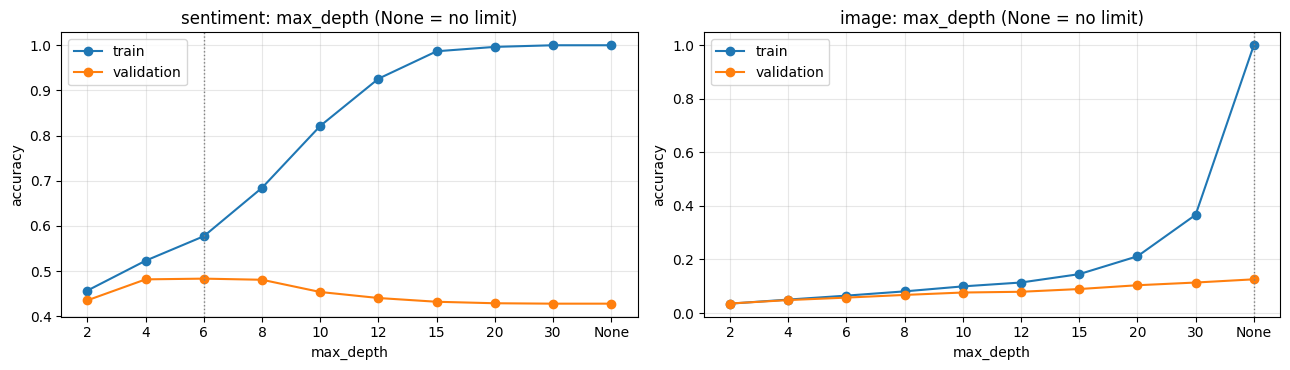

,task,max_depth,train_acc,val_acc,nodes,depth,seconds
0,sentiment,2.0,0.4570,0.4354,7,2,0.49
1,sentiment,4.0,0.5231,0.4817,31,4,0.60
2,sentiment,6.0,0.5773,0.4833,127,6,0.73
3,sentiment,8.0,0.6845,0.4808,479,8,1.12
4,sentiment,10.0,0.8215,0.4537,1259,10,1.95
5,sentiment,12.0,0.9260,0.4404,2059,12,2.89
6,sentiment,15.0,0.9867,0.4321,2729,15,3.55
7,sentiment,20.0,0.9964,0.4288,2879,20,3.74
8,sentiment,30.0,1.0000,0.4279,2963,29,3.82
9,sentiment,NaN,1.0000,0.4279,2963,29,3.92


In [5]:
DEPTHS = [2, 4, 6, 8, 10, 12, 15, 20, 30, None]
depth_rows = {}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, task in zip(axes, TASKS):
    depth_rows[task] = [run(task, "max_depth", max_depth=d) for d in DEPTHS]
    plot_curve(depth_rows[task], "max_depth", f"{task}: max_depth (None = no limit)", ax)
plt.tight_layout(); plt.savefig("report/figures/dt_max_depth.png", dpi=150); plt.show()
pd.concat([show(depth_rows[t]) for t in TASKS])

Sentiment peaks at depth 6 (val 0.483); deeper trees reach train 1.0 while validation drops to 0.428 → **over-fitting**.
Depth 2 is low on both → **under-fitting**. Image needs depth to name 50 classes, but the full tree has a 0.87 train/validation gap.

### 5.2 Minimum rows to split, minimum rows per leaf (no depth limit)

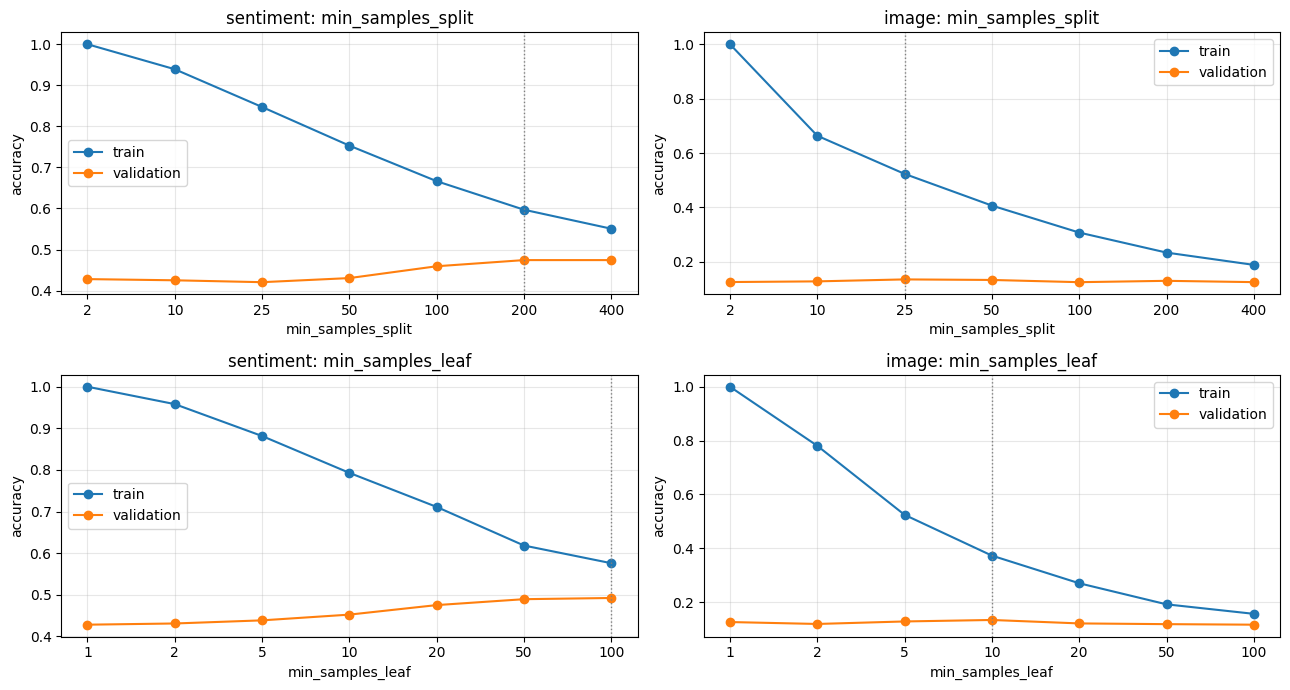

,task,min_samples_split,train_acc,val_acc,nodes,depth,seconds
0,sentiment,2,1.0000,0.4279,2963,29,4.08
1,sentiment,10,0.9391,0.4250,2091,28,3.07
2,sentiment,25,0.8471,0.4204,1451,28,2.36
3,sentiment,50,0.7530,0.4304,951,28,1.73
4,sentiment,100,0.6664,0.4592,539,28,1.28
5,sentiment,200,0.5969,0.4742,245,25,0.94
6,sentiment,400,0.5506,0.4742,95,9,0.74
0,image,2,1.0000,0.1258,17801,129,65.08
1,image,10,0.6636,0.1283,7569,125,29.11
2,image,25,0.5234,0.1355,4639,120,18.58


,task,min_samples_leaf,train_acc,val_acc,nodes,depth,seconds
0,sentiment,1,1.0000,0.4279,2963,29,4.07
1,sentiment,2,0.9582,0.4308,2603,25,3.54
2,sentiment,5,0.8815,0.4383,1879,21,2.72
3,sentiment,10,0.7929,0.4521,1211,17,1.98
4,sentiment,20,0.7110,0.4750,701,15,1.41
5,sentiment,50,0.6182,0.4892,297,12,0.93
6,sentiment,100,0.5757,0.4921,147,8,0.75
0,image,1,1.0000,0.1258,17801,129,67.40
1,image,2,0.7806,0.1187,11913,126,46.05
2,image,5,0.5241,0.1280,5097,105,19.51


In [6]:
SPLITS = [2, 10, 25, 50, 100, 200, 400]
LEAVES = [1, 2, 5, 10, 20, 50, 100]
split_rows, leaf_rows = {}, {}
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for col, task in enumerate(TASKS):
    split_rows[task] = [run(task, "min_samples_split", min_samples_split=s) for s in SPLITS]
    leaf_rows[task] = [run(task, "min_samples_leaf", min_samples_leaf=l) for l in LEAVES]
    plot_curve(split_rows[task], "min_samples_split", f"{task}: min_samples_split", axes[0, col])
    plot_curve(leaf_rows[task], "min_samples_leaf", f"{task}: min_samples_leaf", axes[1, col])
plt.tight_layout(); plt.show()
display(pd.concat([show(split_rows[t]) for t in TASKS]))
display(pd.concat([show(leaf_rows[t]) for t in TASKS]))

### 5.3 Gini vs entropy (at the best depth and the best leaf size)

In [7]:
crit_rows = []
for task in TASKS:
    d = best_of(depth_rows[task])["max_depth"]
    l = best_of(leaf_rows[task])["min_samples_leaf"]
    for crit in ["gini", "entropy"]:
        crit_rows.append(run(task, "criterion", max_depth=d, criterion=crit))
        crit_rows.append(run(task, "criterion", min_samples_leaf=l, criterion=crit))
show(crit_rows)

,task,max_depth,min_samples_leaf,criterion,train_acc,val_acc,nodes,depth,seconds
0,sentiment,6.0,1,gini,0.5773,0.4833,127,6,0.71
1,sentiment,NaN,100,gini,0.5757,0.4921,147,8,0.74
2,sentiment,6.0,1,entropy,0.5609,0.4833,125,6,0.74
3,sentiment,NaN,100,entropy,0.5609,0.4929,151,10,0.79
4,image,NaN,1,gini,1.0000,0.1258,17801,129,66.23
5,image,NaN,10,gini,0.3726,0.1335,2543,78,10.24
6,image,NaN,1,entropy,1.0000,0.0988,18869,47,150.80
7,image,NaN,10,entropy,0.3094,0.0993,2449,39,19.49


### 5.4 Depth × leaf size grid

In [8]:
grid_rows = []
GRID = {"sentiment": ([4, 5, 6, 8, None], [1, 10, 20, 50, 100]),
        "image": ([15, 20, 30, None], [1, 5, 10, 20, 50])}
for task in TASKS:
    depths, leaves = GRID[task]
    for d in depths:
        for l in leaves:
            grid_rows.append(run(task, "depth x leaf", max_depth=d, min_samples_leaf=l))
g = pd.DataFrame(grid_rows)
for task in TASKS:
    print(task, "- validation accuracy (rows = max_depth, columns = min_samples_leaf)")
    display(g[g.task == task].pivot_table(index="max_depth", columns="min_samples_leaf",
                                         values="val_acc", dropna=False).round(4))

sentiment - validation accuracy (rows = max_depth, columns = min_samples_leaf)


min_samples_leaf,1,10,20,50,100
max_depth,,,,,
4.0,0.4817,0.4817,0.4817,0.4817,0.4813
5.0,0.4763,0.4763,0.4763,0.4767,0.4800
6.0,0.4833,0.4821,0.4850,0.4833,0.4858
8.0,0.4808,0.4808,0.4879,0.4917,0.4921
NaN,0.4279,0.4521,0.4750,0.4892,0.4921


image - validation accuracy (rows = max_depth, columns = min_samples_leaf)


min_samples_leaf,1,5,10,20,50
max_depth,,,,,
15.0,0.0895,0.0902,0.0943,0.0917,0.0910
20.0,0.1037,0.1080,0.1087,0.1075,0.1052
30.0,0.1138,0.1190,0.1215,0.1140,0.1125
NaN,0.1258,0.1280,0.1335,0.1207,0.1180


### 5.5 Number of candidate thresholds, and zero-aware thresholds

In [9]:
class PlainQuantileBinner(trees.Binner):
    """Plain quantiles only (our first version)."""
    def fit(self, X):
        q = np.linspace(0, 1, self.n_bins + 1)[1:-1]
        self.thresholds = np.quantile(X, q, axis=0).T
        self.max_t = self.thresholds.shape[1]
        return self


bin_rows = []
for task in TASKS:
    l = best_of(leaf_rows[task])["min_samples_leaf"]
    for nb in [8, 16, 32, 64, 128, 256]:
        bin_rows.append(run(task, "n_bins", min_samples_leaf=l, n_bins=nb))
display(show(bin_rows))

X_tr, y_tr, X_va, y_va = SPLIT["image"]
plain, ours = PlainQuantileBinner(64).fit(X_tr), trees.Binner(64).fit(X_tr)
print(f"image: distinct thresholds per feature  plain {np.mean([len(np.unique(t)) for t in plain.thresholds]):.1f}"
      f"   zero-aware {np.mean([np.isfinite(t).sum() for t in ours.thresholds]):.1f}")
l = best_of(leaf_rows["image"])["min_samples_leaf"]
for name, binner in [("plain quantiles", plain), ("zero-aware", ours)]:
    tree = trees.DecisionTree(min_samples_leaf=l).fit(X_tr, y_tr, 50, binner=binner)
    print(f"   {name:<16} validation accuracy {common.accuracy(y_va, tree.predict(X_va)):.4f}")

,task,min_samples_leaf,n_bins,train_acc,val_acc,nodes,depth,seconds
0,sentiment,100,8,0.5579,0.4817,141,8,0.44
1,sentiment,100,16,0.5720,0.4725,149,9,0.52
2,sentiment,100,32,0.5724,0.4746,147,9,0.62
3,sentiment,100,64,0.5757,0.4921,147,8,0.74
4,sentiment,100,128,0.5736,0.4908,141,9,0.93
5,sentiment,100,256,0.5786,0.4708,145,9,1.34
6,image,10,8,0.3571,0.1192,2469,71,1.99
7,image,10,16,0.3648,0.1138,2527,75,2.98
8,image,10,32,0.3726,0.1273,2569,74,5.27
9,image,10,64,0.3726,0.1335,2543,78,10.45


image: distinct thresholds per feature  plain 10.0   zero-aware 63.0


   plain quantiles  validation accuracy 0.1148


   zero-aware       validation accuracy 0.1335


### 5.6 Raw features vs LDA projection

A tree splits on one feature at a time. LDA (`trees.fit_lda`) projects the data onto the `classes - 1` directions that
best separate the class means (2 for sentiment, 49 for image), so those directions become the axes the tree cuts.
It is fitted on the training rows only; `shrinkage` regularises it.

In [10]:
LDA_SPLIT = {}


def lda_data(task, shrinkage):
    """Train/validation split projected with LDA fitted on the train rows (cached)."""
    if (task, shrinkage) not in LDA_SPLIT:
        X_tr, y_tr, X_va, y_va = SPLIT[task]
        lda = trees.fit_lda(X_tr, y_tr, N_CLASSES[task], shrinkage)
        LDA_SPLIT[(task, shrinkage)] = (trees.apply_lda(X_tr, lda), y_tr, trees.apply_lda(X_va, lda), y_va)
    return LDA_SPLIT[(task, shrinkage)]


lda_rows = []
for task in TASKS:
    for s in [0.0, 0.1, 0.3, 0.5, 0.8]:
        for d in ([2, 3, 4, 6, 8, None] if task == "sentiment" else [10, 15, 20, None]):
            row = run(task, "lda", features=f"lda s={s}", data=lda_data(task, s), max_depth=d, min_samples_leaf=20)
            row["shrinkage"] = s
            lda_rows.append(row)
l = pd.DataFrame(lda_rows)
for task in TASKS:
    print(task, "- validation accuracy on LDA features (rows = shrinkage, columns = max_depth, min_samples_leaf = 20)")
    display(l[l.task == task].pivot_table(index="shrinkage", columns="max_depth", values="val_acc", dropna=False).round(4))

sentiment - validation accuracy on LDA features (rows = shrinkage, columns = max_depth, min_samples_leaf = 20)


max_depth,2.0,3.0,4.0,6.0,8.0,NaN
shrinkage,,,,,,
0.0,0.6129,0.6346,0.6396,0.6529,0.6517,0.6475
0.1,0.6596,0.6683,0.6637,0.6675,0.6658,0.6575
0.3,0.6625,0.6683,0.6650,0.6654,0.6692,0.6633
0.5,0.6529,0.6650,0.6629,0.6687,0.6596,0.6546
0.8,0.6471,0.6512,0.6512,0.6529,0.6508,0.6412


image - validation accuracy on LDA features (rows = shrinkage, columns = max_depth, min_samples_leaf = 20)


max_depth,10.0,15.0,20.0,NaN
shrinkage,,,,
0.0,0.1390,0.1610,0.1620,0.1633
0.1,0.1400,0.1620,0.1590,0.1593
0.3,0.1378,0.1615,0.1638,0.1648
0.5,0.1425,0.1638,0.1645,0.1678
0.8,0.1370,0.1547,0.1590,0.1588


LD1 <= 0.27 ?
    LD2 <= -0.23 ?
        -> class 1   (2570 rows)
    else:
        -> class 2   (2980 rows)
else:
    LD2 <= -0.98 ?
        -> class 1   (610 rows)
    else:
        -> class 0   (3440 rows)
validation accuracy: 0.6625


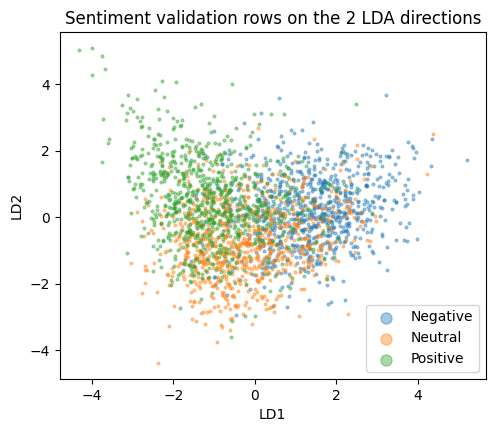

In [11]:
best_sent_lda = max([r for r in lda_rows if r["task"] == "sentiment"], key=lambda r: r["val_acc"])
X_tr, y_tr, X_va, y_va = lda_data("sentiment", best_sent_lda["shrinkage"])
small = trees.DecisionTree(max_depth=2).fit(X_tr, y_tr, 3)          # 3 questions only
print_tree(small, names=["LD1", "LD2"])
print("validation accuracy:", round(common.accuracy(y_va, small.predict(X_va)), 4))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
for c, name in enumerate(common.SENTIMENT_NAMES):
    m = y_va == c
    ax.scatter(X_va[m, 0], X_va[m, 1], s=4, alpha=0.4, label=name)
ax.set_xlabel("LD1"); ax.set_ylabel("LD2"); ax.set_title("Sentiment validation rows on the 2 LDA directions")
ax.legend(markerscale=4); plt.savefig("report/figures/dt_sentiment_lda.png", dpi=150); plt.show()

## 6. Selected tree per task (best validation accuracy)

In [12]:
table = pd.DataFrame(results)
for task in TASKS:
    table[table.task == task].sort_values("val_acc", ascending=False).to_csv(
        f"decision_tree/outputs/{task}_experiments.csv", index=False)

best = {task: best_of([r for r in results if r["task"] == task]) for task in TASKS}
pd.DataFrame([best[t] for t in TASKS])[["task", "features", "max_depth", "min_samples_split", "min_samples_leaf",
                                         "criterion", "n_bins", "train_acc", "val_acc", "nodes", "depth", "seconds"]]

,task,features,max_depth,min_samples_split,min_samples_leaf,criterion,n_bins,train_acc,val_acc,nodes,depth,seconds
0,sentiment,lda s=0.3,8.0,2,20,gini,64,0.7252,0.6692,339,8,0.01
1,image,lda s=0.5,NaN,2,20,gini,64,0.3412,0.1678,1217,25,0.50


## 7. Error analysis

In [13]:
def settings_of(row):
    return dict(max_depth=None if pd.isna(row["max_depth"]) else int(row["max_depth"]),
                min_samples_split=int(row["min_samples_split"]), min_samples_leaf=int(row["min_samples_leaf"]),
                criterion=row["criterion"], n_bins=int(row["n_bins"]))


def shrinkage_of(row):
    return float(row["features"].split("=")[1]) if row["features"].startswith("lda") else None


def per_class_table(y_true, y_pred, n_classes, names=None):
    cm = common.confusion_matrix(y_true, y_pred, n_classes)
    p, r = common.per_class_precision(cm), common.per_class_recall(cm)
    f1 = np.where(p + r > 0, 2 * p * r / np.maximum(p + r, 1e-12), 0)
    return cm, pd.DataFrame({"precision": p, "recall": r, "f1": f1}, index=names or range(n_classes)).round(3)


final_trees, val_pred = {}, {}
for task in TASKS:
    row, s = best[task], shrinkage_of(best[task])
    X_tr, y_tr, X_va, y_va = SPLIT[task] if s is None else lda_data(task, s)
    tree = trees.DecisionTree(**settings_of(row)).fit(X_tr, y_tr, N_CLASSES[task])
    final_trees[task], val_pred[task] = tree, tree.predict(X_va)
    np.save(f"decision_tree/outputs/{task}_val_pred.npy", val_pred[task])       # read by final/compare.ipynb
    np.save(f"decision_tree/outputs/{task}_val_proba.npy", tree.predict_proba(X_va))
    print(f"{task}: {row['features']} {settings_of(row)}  validation {common.accuracy(y_va, val_pred[task]):.4f}")

y_va = SPLIT["sentiment"][3]
cm, per_class = per_class_table(y_va, val_pred["sentiment"], 3, common.SENTIMENT_NAMES)
print("\nSentiment confusion matrix (rows = true, columns = predicted)")
display(pd.DataFrame(cm, index=common.SENTIMENT_NAMES, columns=common.SENTIMENT_NAMES))
display(per_class)

sentiment: lda s=0.3 {'max_depth': 8, 'min_samples_split': 2, 'min_samples_leaf': 20, 'criterion': 'gini', 'n_bins': 64}  validation 0.6692


image: lda s=0.5 {'max_depth': None, 'min_samples_split': 2, 'min_samples_leaf': 20, 'criterion': 'gini', 'n_bins': 64}  validation 0.1678

Sentiment confusion matrix (rows = true, columns = predicted)


,Negative,Neutral,Positive
Negative,609,130,61
Neutral,175,452,173
Positive,90,165,545


,precision,recall,f1
Negative,0.697,0.761,0.728
Neutral,0.605,0.565,0.584
Positive,0.700,0.681,0.690


Image: 5 hardest and 5 easiest classes (by recall)


,precision,recall,f1
19,0.000,0.000,0.000
29,0.025,0.012,0.017
9,0.015,0.012,0.014
0,0.026,0.025,0.026
31,0.049,0.025,0.033
13,0.384,0.412,0.398
28,0.330,0.438,0.376
5,0.594,0.475,0.528
48,0.704,0.475,0.567
46,0.725,0.625,0.671


Most frequent confusions (true -> predicted, out of 80):
    4 ->  2   17
    3 ->  2   13
   25 -> 12   13
   11 -> 28   9
   14 -> 12   9
   22 -> 42   9
    2 ->  4   8
    9 ->  8   8


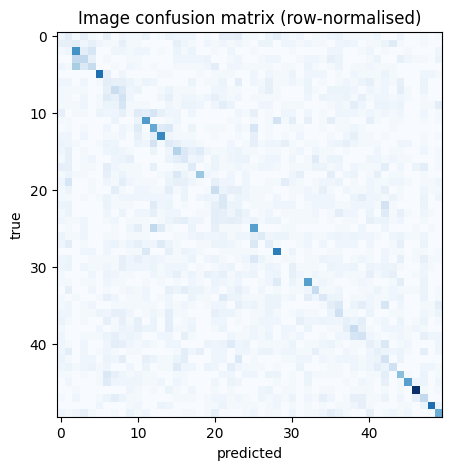

In [14]:
y_va = SPLIT["image"][3]
cm, per_class = per_class_table(y_va, val_pred["image"], 50)
print("Image: 5 hardest and 5 easiest classes (by recall)")
display(pd.concat([per_class.sort_values("recall").head(5), per_class.sort_values("recall").tail(5)]))
print("Most frequent confusions (true -> predicted, out of 80):")
for t, p, n in common.most_confused_pairs(cm, 8):
    print(f"   {t:2d} -> {p:2d}   {n}")

fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues")
ax.set_title("Image confusion matrix (row-normalised)"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.savefig("report/figures/dt_image_confusion.png", dpi=150); plt.show()

In [15]:
for task in TASKS:      # impurity-based feature importance of the selected trees
    tree = final_trees[task]
    n_feat = tree.binner.thresholds.shape[0]
    imp = tree.feature_importance(n_feat)
    top = np.argsort(imp)[::-1][:10]
    print(f"{task}: uses {(imp > 0).sum()} of {n_feat} features; top-10 hold {imp[top].sum():.0%} of the importance")
    print("   ", ", ".join(f"{f} ({imp[f]:.2f})" for f in top))

sentiment: uses 2 of 2 features; top-10 hold 100% of the importance
    0 (0.62), 1 (0.38)
image: uses 49 of 49 features; top-10 hold 52% of the importance
    0 (0.10), 4 (0.06), 2 (0.06), 7 (0.05), 8 (0.05), 3 (0.05), 5 (0.04), 11 (0.04), 6 (0.04), 9 (0.03)


## 8. Test predictions for Kaggle

Selected settings, retrained on all training rows (LDA refitted on all training rows if used).

In [16]:
for task in TASKS:
    row, s = best[task], shrinkage_of(best[task])
    X, y = DATA[task]
    X_test, test_ids = TEST[task]
    if s is not None:
        lda = trees.fit_lda(X, y, N_CLASSES[task], s)
        X, X_test = trees.apply_lda(X, lda), trees.apply_lda(X_test, lda)
    start = time.time()
    tree = trees.DecisionTree(**settings_of(row)).fit(X, y, N_CLASSES[task])
    fit_s = time.time() - start
    pred = tree.predict(X_test)
    pd.DataFrame({"id": test_ids, "label": pred}).to_csv(f"decision_tree/outputs/{task}_test_pred.csv", index=False)
    print(f"{task}: saved decision_tree/outputs/{task}_test_pred.csv  (train {fit_s:.1f}s, {tree.n_nodes} nodes)")

sentiment: saved decision_tree/outputs/sentiment_test_pred.csv  (train 0.0s, 361 nodes)


image: saved decision_tree/outputs/image_test_pred.csv  (train 0.6s, 1499 nodes)


## 9. Findings

* **Depth:** sentiment validation peaks at depth 6 (0.483) and falls to 0.428 at full depth while train reaches 1.0 (over-fitting);
  depth 2 under-fits. A full image tree has train 1.0 vs validation 0.126.
* **Pre-pruning:** `min_samples_leaf` is a smoother brake than a depth cap (sentiment 0.492 at 100, image 0.134 at 10).
  Gini ≈ entropy on sentiment; Gini is better on image (0.134 vs 0.099).
* **Thresholds:** zero-aware thresholds give 63 instead of ~10 real choices per image feature (0.115 → 0.134); more than 64 bins does not help.
* **LDA:** trees split one feature at a time. On the 2 LDA directions, a 3-question tree already reaches 0.663 on sentiment
  and the best tree 0.669 (raw: 0.492). Image improves less (0.134 → 0.168).
* **Hard classes:** Neutral sentiment (recall 0.57) is confused with both other classes. On image, classes 2, 3 and 4 are often confused.